In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [9]:
ROE_ROA_df = pd.read_excel('FI_T5.xlsx')

In [10]:

columns = ['Stkcd', 'Accper','Typrep','F050202B', 'F050502B']
ROE_ROA_df = ROE_ROA_df[columns]
ROE_ROA_df = ROE_ROA_df[ROE_ROA_df['Typrep'] == 'A']
ROE_ROA_df = ROE_ROA_df.drop(columns=['Typrep'])
ROE_ROA_df['ROA'] = ROE_ROA_df['F050202B']
ROE_ROA_df['ROE'] = ROE_ROA_df['F050502B']
ROE_ROA_df.drop(columns=['F050202B', 'F050502B'], inplace=True)

print(ROE_ROA_df.head())

    Stkcd      Accper       ROA       ROE
2  000001  2000-06-30       NaN       NaN
3  000001  2000-12-31  0.009116  0.172282
4  000001  2001-06-30  0.002929   0.04602
5  000001  2001-12-31  0.004323  0.112624
6  000001  2002-03-31  0.001594  0.049452


In [11]:
EPS_df = pd.read_excel('FI_T9.xlsx')
columns = ['Stkcd', 'Accper','Typrep','F090102C']
EPS_df = EPS_df[columns]
EPS_df = EPS_df[EPS_df['Typrep'] == 'A']
EPS_df['EPS'] = EPS_df['F090102C']
EPS_df.drop(columns=['Typrep', 'F090102C'], inplace=True)
data = pd.merge(ROE_ROA_df, EPS_df, on=['Stkcd', 'Accper'])

In [12]:
data['Accper'] = pd.to_datetime(data['Accper'], format='%Y-%m-%d')

In [13]:
R_D_expense = pd.read_csv('FS_Comins.csv',dtype={'Stkcd': str})
R_D_expense

,Stkcd,ShortName,Accper,Typrep,B001216000
0,000001,深发展A,2000-01-01,A,NaN
1,000001,深发展A,2000-06-30,A,NaN
2,000001,深发展A,2000-12-31,A,NaN
3,000001,深发展A,2001-01-01,A,NaN
4,000001,深发展A,2001-06-30,A,NaN
...,...,...,...,...,...
562950,873833,美心翼申,2023-03-31,B,2245194.78
562951,873833,美心翼申,2023-06-30,A,4953029.32
562952,873833,美心翼申,2023-06-30,B,4953029.32
562953,873833,美心翼申,2023-12-31,A,8452782.18


In [14]:
columns = ['Stkcd', 'Accper','Typrep','B001216000']
R_D_expense =R_D_expense[columns]
R_D_expense = R_D_expense[R_D_expense['Typrep'] == 'A']
R_D_expense['RDexpense'] =R_D_expense['B001216000']
R_D_expense.drop(columns=['Typrep', 'B001216000'], inplace=True)
R_D_expense['Accper'] = pd.to_datetime(R_D_expense['Accper'], format='%Y-%m-%d')
data = pd.merge(data, R_D_expense, on=['Stkcd', 'Accper'])

In [15]:
data

,Stkcd,Accper,ROA,ROE,EPS,RDexpense
0,000001,2000-06-30,NaN,NaN,0.317187,NaN
1,000001,2000-12-31,0.009116,0.172282,0.260328,NaN
2,000001,2001-06-30,0.002929,0.04602,0.283587,NaN
3,000001,2001-12-31,0.004323,0.112624,0.206782,NaN
4,000001,2002-03-31,0.001594,0.049452,NaN,NaN
...,...,...,...,...,...,...
239125,873833,2022-06-30,0.033906,0.052587,NaN,4978196.78
239126,873833,2022-12-31,0.071819,0.10893,NaN,9349067.59
239127,873833,2023-03-31,0.010737,0.015373,NaN,2245194.78
239128,873833,2023-06-30,0.038746,0.055575,NaN,4953029.32


In [16]:
asset_lia_df = pd.read_csv('FS_Combas.csv',dtype={'Stkcd': str})
columns = ['Stkcd', 'Accper','Typrep','A001000000','A002000000']
asset_lia_df =asset_lia_df[columns]
asset_lia_df = asset_lia_df[asset_lia_df['Typrep'] == 'A']
asset_lia_df['total_asset'] =asset_lia_df['A001000000']
asset_lia_df['total_lia'] =asset_lia_df['A002000000']
asset_lia_df.drop(columns=['Typrep','A001000000','A002000000'], inplace=True)
asset_lia_df['Accper'] = pd.to_datetime(asset_lia_df['Accper'], format='%Y-%m-%d')
quarter_data = pd.merge(data, asset_lia_df, on=['Stkcd', 'Accper'])

In [18]:
len(quarter_data['Stkcd'].unique())

5607

In [19]:
month_data = pd.read_csv('TRD_Mnth.csv',dtype={'Stkcd': str})
columns = ['Stkcd', 'Trdmnt','Mclsprc','Msmvosd','Mretnd']
new_name = ['Stkcd', 'Trdmnt','close','market_cap','return']
month_data = month_data[columns]
month_data.columns = new_name
month_data

,Stkcd,Trdmnt,close,market_cap,return
0,000001,2000-01,18.53,19843822.88,0.061891
1,000001,2000-02,18.32,19618933.36,-0.011333
2,000001,2000-03,18.37,19672478.48,0.002729
3,000001,2000-04,19.05,20400692.17,0.037017
4,000001,2000-05,18.00,19276244.57,-0.055118
...,...,...,...,...,...
679944,873593,2023-06,133.40,2396565.82,0.318182
679945,873593,2023-07,86.00,1545012.45,-0.355322
679946,873593,2023-08,77.50,1392307.73,-0.098837
679947,873593,2023-09,36.06,1295654.62,-0.056516


In [20]:
month_data['Trdmnt'] = pd.to_datetime(month_data['Trdmnt'], format='%Y-%m') + pd.offsets.MonthEnd(0)
month_data

,Stkcd,Trdmnt,close,market_cap,return
0,000001,2000-01-31,18.53,19843822.88,0.061891
1,000001,2000-02-29,18.32,19618933.36,-0.011333
2,000001,2000-03-31,18.37,19672478.48,0.002729
3,000001,2000-04-30,19.05,20400692.17,0.037017
4,000001,2000-05-31,18.00,19276244.57,-0.055118
...,...,...,...,...,...
679944,873593,2023-06-30,133.40,2396565.82,0.318182
679945,873593,2023-07-31,86.00,1545012.45,-0.355322
679946,873593,2023-08-31,77.50,1392307.73,-0.098837
679947,873593,2023-09-30,36.06,1295654.62,-0.056516


In [21]:
len(month_data['Stkcd'].unique())

5525

In [22]:
company_basic = pd.read_csv('TRD_Co.csv',dtype={'Stkcd': str})
columns = ['Stkcd','Listdt','Estbdt','Markettype']
company_basic = company_basic[columns]
company_basic

,Stkcd,Listdt,Estbdt,Markettype
0,000070,2000-05-11,1997-07-29,4
1,000096,2000-07-24,1999-02-18,4
2,000099,2000-07-31,1999-02-11,4
3,000100,2004-01-30,1997-07-17,4
4,000150,2000-08-07,1993-02-19,4
...,...,...,...,...
4646,873679,2023-11-10,2015-12-23,64
4647,873693,2023-10-27,2010-02-05,64
4648,873703,2023-12-05,2001-02-21,64
4649,873726,2023-10-19,2015-07-15,64


In [23]:
len(company_basic['Stkcd'].unique())

4651

In [24]:
stock = set(company_basic['Stkcd'].tolist()).intersection(month_data['Stkcd'].tolist()).intersection(quarter_data['Stkcd'].tolist())
company_basic = company_basic[company_basic['Stkcd'].isin(stock)]
month_data = month_data[month_data['Stkcd'].isin(stock)]
quarter_data = quarter_data[quarter_data['Stkcd'].isin(stock)]


In [25]:
month_data['Trdmnt'] = pd.to_datetime(month_data['Trdmnt'])
quarter_data['Accper'] = pd.to_datetime(quarter_data['Accper'])
month_data.set_index('Stkcd', inplace=True)
quarter_data.set_index('Stkcd', inplace=True)


In [39]:
month_data

,Trdmnt,close,market_cap,return
Stkcd,,,,
000070,2000-05-31,31.26,1969380.00,NaN
000070,2000-06-30,29.11,1833930.00,-0.068778
000070,2000-07-31,29.41,1852830.00,0.010306
000070,2000-08-31,27.54,1735020.00,-0.063584
000070,2000-09-30,25.00,1575000.00,-0.092229
...,...,...,...,...
873593,2023-06-30,133.40,2396565.82,0.318182
873593,2023-07-31,86.00,1545012.45,-0.355322
873593,2023-08-31,77.50,1392307.73,-0.098837


In [40]:
def get_latest_quarter_date(group, quarter_data):
    # 筛选出相同股票代码的季度数据
    stock_data = quarter_data[quarter_data.index == group.name]
    
    # 找到该月之前最近的季度日期
    latest_quarters = []
    for row in group.itertuples():
        # 使用getattr()访问Trdmnt字段
        latest_quarter = stock_data[stock_data['Accper'] <= getattr(row, 'Trdmnt')].sort_values('Accper', ascending=False).head(1)
        
        if not latest_quarter.empty:
            latest_quarters.append(latest_quarter['Accper'].iloc[0])
        else:
            latest_quarters.append(pd.NaT)
    
    group['latest_quarter_date'] = latest_quarters
    return group

# 使用groupby应用到每个股票
month_merged = month_data.groupby(month_data.index).apply(lambda group: get_latest_quarter_date(group, quarter_data))


In [ ]:
month_merged = month_merged.droplevel(level=0)
month_merged.reset_index(inplace= True)
month_merged

,Stkcd,Trdmnt,close,market_cap,return,latest_quarter_date
0,000070,2000-05-31,31.26,1969380.00,NaN,NaT
1,000070,2000-06-30,29.11,1833930.00,-0.068778,2000-06-30
2,000070,2000-07-31,29.41,1852830.00,0.010306,2000-06-30
3,000070,2000-08-31,27.54,1735020.00,-0.063584,2000-06-30
4,000070,2000-09-30,25.00,1575000.00,-0.092229,2000-06-30
...,...,...,...,...,...,...
442022,873593,2023-06-30,133.40,2396565.82,0.318182,2023-06-30
442023,873593,2023-07-31,86.00,1545012.45,-0.355322,2023-06-30
442024,873593,2023-08-31,77.50,1392307.73,-0.098837,2023-06-30
442025,873593,2023-09-30,36.06,1295654.62,-0.056516,2023-09-30


In [45]:

df_merged = pd.merge(month_merged, quarter_data, how='left', left_on=['Stkcd', 'latest_quarter_date'], right_on=['Stkcd', 'Accper'])
df_merged = pd.merge(df_merged, company_basic, on='Stkcd')
df_merged

,Stkcd,Trdmnt,close,market_cap,return,latest_quarter_date,Accper,ROA,ROE,EPS,RDexpense,total_asset,total_lia,Listdt,Estbdt,Markettype
0,000070,2000-05-31,31.26,1969380.00,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,2000-05-11,1997-07-29,4
1,000070,2000-06-30,29.11,1833930.00,-0.068778,2000-06-30,2000-06-30,NaN,NaN,NaN,NaN,1.305490e+09,4.782167e+08,2000-05-11,1997-07-29,4
2,000070,2000-07-31,29.41,1852830.00,0.010306,2000-06-30,2000-06-30,NaN,NaN,NaN,NaN,1.305490e+09,4.782167e+08,2000-05-11,1997-07-29,4
3,000070,2000-08-31,27.54,1735020.00,-0.063584,2000-06-30,2000-06-30,NaN,NaN,NaN,NaN,1.305490e+09,4.782167e+08,2000-05-11,1997-07-29,4
4,000070,2000-09-30,25.00,1575000.00,-0.092229,2000-06-30,2000-06-30,NaN,NaN,NaN,NaN,1.305490e+09,4.782167e+08,2000-05-11,1997-07-29,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
442022,873593,2023-06-30,133.40,2396565.82,0.318182,2023-06-30,2023-06-30,0.096618,0.113393,2.093781,11110080.09,7.563485e+08,6.834454e+07,2023-04-13,2008-04-16,64
442023,873593,2023-07-31,86.00,1545012.45,-0.355322,2023-06-30,2023-06-30,0.096618,0.113393,2.093781,11110080.09,7.563485e+08,6.834454e+07,2023-04-13,2008-04-16,64
442024,873593,2023-08-31,77.50,1392307.73,-0.098837,2023-06-30,2023-06-30,0.096618,0.113393,2.093781,11110080.09,7.563485e+08,6.834454e+07,2023-04-13,2008-04-16,64
442025,873593,2023-09-30,36.06,1295654.62,-0.056516,2023-09-30,2023-09-30,0.12436,0.145675,0.870648,16213313.24,7.134106e+08,6.024103e+07,2023-04-13,2008-04-16,64


In [48]:
df_merged.columns

Index(['Stkcd', 'Trdmnt', 'close', 'market_cap', 'return',
       'latest_quarter_date', 'Accper', 'ROA', 'ROE', 'EPS', 'RDexpense',
       'total_asset', 'total_lia', 'Listdt', 'Estbdt', 'Markettype'],
      dtype='object')

#### 1(a)

In [109]:
final_df = df_merged.copy()
final_df.set_index(['Stkcd','Trdmnt'], inplace=True)
final_df['monthly_PE'] = final_df['close'] / final_df['EPS']
total_share = final_df['market_cap']*10**3/final_df['close']
BVPS = (final_df['total_asset'] - final_df['total_lia'])/total_share
final_df['monthly_PB'] = final_df['close']/BVPS
final_df['monthly_PB'] = final_df.apply(
    lambda row: float('nan') if  row['monthly_PB'] == float('inf') else row['monthly_PB'], axis=1
)
final_df['RD/assets'] = final_df['RDexpense']/final_df['total_asset']
final_df['Estbdt'] = pd.to_datetime(final_df['Estbdt'], format='%Y-%m-%d')
final_df['Listdt'] = pd.to_datetime(final_df['Listdt'], format='%Y-%m-%d')
final_df['quarter_age'] = (final_df.index.get_level_values('Trdmnt') - final_df['Estbdt'])
final_df


close  market_cap    return latest_quarter_date  \
Stkcd  Trdmnt                                                         
000070 2000-05-31   31.26  1969380.00       NaN                 NaT   
       2000-06-30   29.11  1833930.00 -0.068778          2000-06-30   
       2000-07-31   29.41  1852830.00  0.010306          2000-06-30   
       2000-08-31   27.54  1735020.00 -0.063584          2000-06-30   
       2000-09-30   25.00  1575000.00 -0.092229          2000-06-30   
...                   ...         ...       ...                 ...   
873593 2023-06-30  133.40  2396565.82  0.318182          2023-06-30   
       2023-07-31   86.00  1545012.45 -0.355322          2023-06-30   
       2023-08-31   77.50  1392307.73 -0.098837          2023-06-30   
       2023-09-30   36.06  1295654.62 -0.056516          2023-09-30   
873665 2023-09-30    5.88   194000.04       NaN          2023-09-30   

                      Accper       ROA       ROE       EPS    RDexpense  \
Stkcd  Trdmnt                                                             
000070 2000-05-31        NaT       NaN       NaN       NaN          NaN   
       2000-06-30 2000-06-30       NaN       NaN       NaN          NaN   
       2000-07-31 2000-06-30       NaN       NaN       NaN          NaN   
       2000-08-31 2000-06-30       NaN       NaN       NaN          NaN   
       2000-09-30 2000-06-30       NaN       NaN       NaN          NaN   
...                      ...       ...       ...       ...          ...   
873593 2023-06-30 2023-06-30  0.096618  0.113393  2.093781  11110080.09   
       2023-07-31 2023-06-30  0.096618  0.113393  2.093781  11110080.09   
       2023-08-31 2023-06-30  0.096618  0.113393  2.093781  11110080.09   
       2023-09-30 2023-09-30   0.12436  0.145675  0.870648  16213313.24   
873665 2023-09-30 2023-09-30  0.079977  0.096835  0.527178  10598140.80   

                    total_asset     total_lia     Listdt     Estbdt  \
Stkcd  Trdmnt                                                         
000070 2000-05-31           NaN           NaN 2000-05-11 1997-07-29   
       2000-06-30  1.305490e+09  4.782167e+08 2000-05-11 1997-07-29   
       2000-07-31  1.305490e+09  4.782167e+08 2000-05-11 1997-07-29   
       2000-08-31  1.305490e+09  4.782167e+08 2000-05-11 1997-07-29   
       2000-09-30  1.305490e+09  4.782167e+08 2000-05-11 1997-07-29   
...                         ...           ...        ...        ...   
873593 2023-06-30  7.563485e+08  6.834454e+07 2023-04-13 2008-04-16   
       2023-07-31  7.563485e+08  6.834454e+07 2023-04-13 2008-04-16   
       2023-08-31  7.563485e+08  6.834454e+07 2023-04-13 2008-04-16   
       2023-09-30  7.134106e+08  6.024103e+07 2023-04-13 2008-04-16   
873665 2023-09-30  7.825638e+08  1.245995e+08 2023-09-26 2001-08-23   

                   Markettype monthly_PE  monthly_PB  RD/assets quarter_age  
Stkcd  Trdmnt                                                                
000070 2000-05-31           4        NaN         NaN        NaN   1037 days  
       2000-06-30           4        NaN    2.216837        NaN   1067 days  
       2000-07-31           4        NaN    2.239683        NaN   1098 days  
       2000-08-31           4        NaN    2.097275        NaN   1129 days  
       2000-09-30           4        NaN    1.903844        NaN   1159 days  
...                       ...        ...         ...        ...         ...  
873593 2023-06-30          64   63.71249    3.483360   0.014689   5553 days  
       2023-07-31          64  41.074019    2.245645   0.014689   5584 days  
       2023-08-31          64  37.014377    2.023691   0.014689   5615 days  
       2023-09-30          64  41.417427    1.983642   0.022726   5645 days  
873665 2023-09-30          64  11.153728    0.294849   0.013543   8073 days  

[442027 rows x 18 columns]

### 1(b)

In [110]:
main_board = final_df[(final_df['Markettype'] == 1) | (final_df['Markettype'] == 2) | (final_df['Markettype'] == 4)| (final_df['Markettype'] == 8)]
GEM_board = final_df[final_df['Markettype'] == 16]


In [112]:
def calc_monthly_summary_stats(df):
    # 计算月度股票收益率、P/E、P/B的统计量
    return_stats = df['return'].agg(
        count='count',
        mean='mean',
        std='std',
        median='median',
        min='min',
        p25=lambda x: x.quantile(0.25),
        p75=lambda x: x.quantile(0.75),
        max='max',
    ).to_frame().T

    PE_stats = df['monthly_PE'].agg(
       count='count',
        mean='mean',
        std='std',
        median='median',
        min='min',
        p25=lambda x: x.quantile(0.25),
        p75=lambda x: x.quantile(0.75),
        max='max',
    ).to_frame().T

    PB_stats = df['monthly_PB'].agg(
       count='count',
        mean='mean',
        std='std',
        median='median',
        min='min',
        p25=lambda x: x.quantile(0.25),
        p75=lambda x: x.quantile(0.75),
        max='max',
    ).to_frame().T

    # 合并月度统计结果
    monthly_stats = pd.concat([return_stats, PE_stats, PB_stats], axis=0)
    monthly_stats.index = ['return', 'P/E', 'P/B']  # 设置行标签为指标名称

    return monthly_stats

def calc_quarterly_summary_stats(df):
    df['latest_quarter_date'] = pd.to_datetime(df['latest_quarter_date'])
    df_unique_quarter = df.reset_index().drop_duplicates(subset=['Stkcd', 'latest_quarter_date'])

    ROA_stats = df_unique_quarter['ROA'].agg(
        count='count',
        mean='mean',
        std='std',
        median='median',
        min='min',
        p25=lambda x: x.quantile(0.25),
        p75=lambda x: x.quantile(0.75),
        max='max',
    ).to_frame().T

    ROE_stats = df_unique_quarter['ROE'].agg(
       count='count',
        mean='mean',
        std='std',
        median='median',
        min='min',
        p25=lambda x: x.quantile(0.25),
        p75=lambda x: x.quantile(0.75),
        max='max',
    ).to_frame().T

    RD_assets_stats = df_unique_quarter['RD/assets'].agg(
       count='count',
        mean='mean',
        std='std',
        median='median',
        min='min',
        p25=lambda x: x.quantile(0.25),
        p75=lambda x: x.quantile(0.75),
        max='max',
    ).to_frame().T

    quarter_age_stats = df_unique_quarter['quarter_age'].agg(
        count='count',
        mean='mean',
        std='std',
        median='median',
        min='min',
        p25=lambda x: x.quantile(0.25),
        p75=lambda x: x.quantile(0.75),
        max='max',
    ).to_frame().T

    # 合并季度统计结果
    quarterly_stats = pd.concat([ROA_stats, ROE_stats, RD_assets_stats, quarter_age_stats], axis=0)
    quarterly_stats.index = ['ROA', 'ROE', 'R&D/Assets', 'Firm Age']  # 设置行标签为指标名称

    return quarterly_stats


main_board_monthly_stats = calc_monthly_summary_stats(main_board)
GEM_board_monthly_stats = calc_monthly_summary_stats(GEM_board)

# 计算主板和创业板的季度统计量
main_board_quarterly_stats = calc_quarterly_summary_stats(main_board)
GEM_board_quarterly_stats = calc_quarterly_summary_stats(GEM_board)


In [113]:
main_board_final = pd.concat([main_board_monthly_stats.T, main_board_quarterly_stats.T], axis=1)
GEM_board_final = pd.concat([GEM_board_monthly_stats.T, GEM_board_quarterly_stats.T], axis=1)


In [115]:
import pandas as pd

def clean_firm_age(df):
    if "Firm Age" in df.columns:
        df['Firm Age'] = df['Firm Age'].apply(
    lambda x: f"{x.days} days" if isinstance(x, pd.Timedelta) else str(x) + ' days'
)

    return df

main_board_final = clean_firm_age(main_board_final)
GEM_board_final = clean_firm_age(GEM_board_final)

In [116]:
main_board_final

,return,P/E,P/B,ROA,ROE,R&D/Assets,Firm Age
count,320120.000000,3.058970e+05,321458.000000,107907.0,107321.0,41509.0,110460 days
mean,0.011732,3.566475e+01,0.136504,0.027573,0.036929,0.013488,6076 days
std,0.152489,5.689869e+03,797.314643,0.058181,0.720329,0.015985,2478 days
median,-0.001138,2.875487e+01,1.614077,0.020087,0.039307,0.008991,6042 days
min,-0.882166,-1.378000e+06,-288251.355131,-1.871948,-174.89472,-0.002272,30 days
p25,-0.068997,1.466306e+01,0.942146,0.006041,0.013258,0.003366,4316 days
p75,0.074271,5.345658e+01,2.746548,0.04538,0.081933,0.018438,7711 days
max,12.752211,4.207527e+05,7219.120447,4.48898,14.02095,0.272267,24744 days


In [117]:
GEM_board_final

,return,P/E,P/B,ROA,ROE,R&D/Assets,Firm Age
count,98488.000000,9.227100e+04,99273.000000,34592.0,34492.0,20347.0,35027 days
mean,0.013845,9.639858e+01,2.821514,0.03001,-0.016487,0.018416,6153 days
std,0.184706,1.083280e+04,20.201810,0.059997,9.459159,0.01831,1979 days
median,-0.003256,4.184850e+01,1.963411,0.02349,0.035107,0.013414,6078 days
min,-0.863517,-7.464286e+05,-1566.034410,-1.878509,-1756.043203,0.0,492 days
p25,-0.082521,2.435633e+01,1.198025,0.007091,0.010993,0.006663,4737 days
p75,0.081568,7.204483e+01,3.249252,0.0516,0.075229,0.024007,7416 days
max,6.399758,2.087500e+06,3634.632784,0.879588,1.319279,0.253642,15538 days


In [118]:


def style_table(df):
    
    df.iloc[0, :-1] = df.iloc[0, :-1].astype(int)

    # 应用样式
    styled_df = df.style.set_properties(**{
        'border': '1px solid black',
        'color': 'black',
        'background-color': '#f7f7f7',  # 淡灰色背景
        'text-align': 'center'
    }).set_table_styles([ 
        {'selector': 'th', 'props': [('background-color', '#4f81bd'),  # 深蓝色表头
                                     ('color', 'white'),
                                     ('font-weight', 'bold'),
                                     ('text-align', 'center')]},
        {'selector': 'td', 'props': [('padding', '5px')]},
    ]).format(precision=2, subset=df.select_dtypes(include=['float', 'int']).columns)  # 默认保留两位小数

    return styled_df

# 应用美化
styled_main_board = style_table(main_board_final)
styled_GEM_board = style_table(GEM_board_final)



In [119]:
styled_main_board 

,return,P/E,P/B,ROA,ROE,R&D/Assets,Firm Age
count,320120.00,305897.00,321458.00,107907,107321,41509,110460 days
mean,0.01,35.66,0.14,0.027573,0.036929,0.013488,6076 days
std,0.15,5689.87,797.31,0.058181,0.720329,0.015985,2478 days
median,-0.00,28.75,1.61,0.020087,0.039307,0.008991,6042 days
min,-0.88,-1378000.00,-288251.36,-1.871948,-174.894720,-0.002272,30 days
p25,-0.07,14.66,0.94,0.006041,0.013258,0.003366,4316 days
p75,0.07,53.46,2.75,0.045380,0.081933,0.018438,7711 days
max,12.75,420752.69,7219.12,4.488980,14.020950,0.272267,24744 days


In [120]:
styled_GEM_board

,return,P/E,P/B,ROA,ROE,R&D/Assets,Firm Age
count,98488.00,92271.00,99273.00,34592,34492,20347,35027 days
mean,0.01,96.40,2.82,0.030010,-0.016487,0.018416,6153 days
std,0.18,10832.80,20.20,0.059997,9.459159,0.018310,1979 days
median,-0.00,41.85,1.96,0.023490,0.035107,0.013414,6078 days
min,-0.86,-746428.57,-1566.03,-1.878509,-1756.043203,0.000000,492 days
p25,-0.08,24.36,1.20,0.007091,0.010993,0.006663,4737 days
p75,0.08,72.04,3.25,0.051600,0.075229,0.024007,7416 days
max,6.40,2087500.00,3634.63,0.879588,1.319279,0.253642,15538 days


#### 2.

In [121]:
main_board 

close  market_cap    return latest_quarter_date     Accper  \
Stkcd  Trdmnt                                                                   
000070 2000-05-31  31.26  1969380.00       NaN                 NaT        NaT   
       2000-06-30  29.11  1833930.00 -0.068778          2000-06-30 2000-06-30   
       2000-07-31  29.41  1852830.00  0.010306          2000-06-30 2000-06-30   
       2000-08-31  27.54  1735020.00 -0.063584          2000-06-30 2000-06-30   
       2000-09-30  25.00  1575000.00 -0.092229          2000-06-30 2000-06-30   
...                  ...         ...       ...                 ...        ...   
605599 2023-05-31  11.58  6793728.92 -0.060827          2023-03-31 2023-03-31   
       2023-06-30  13.21  7750013.74  0.180484          2023-06-30 2023-06-30   
       2023-07-31  13.92  8166554.98  0.053747          2023-06-30 2023-06-30   
       2023-08-31  13.56  7955350.97 -0.025862          2023-06-30 2023-06-30   
       2023-09-30  14.54  8530295.21  0.072271          2023-09-30 2023-09-30   

                        ROA       ROE       EPS   RDexpense   total_asset  \
Stkcd  Trdmnt                                                               
000070 2000-05-31       NaN       NaN       NaN         NaN           NaN   
       2000-06-30       NaN       NaN       NaN         NaN  1.305490e+09   
       2000-07-31       NaN       NaN       NaN         NaN  1.305490e+09   
       2000-08-31       NaN       NaN       NaN         NaN  1.305490e+09   
       2000-09-30       NaN       NaN       NaN         NaN  1.305490e+09   
...                     ...       ...       ...         ...           ...   
605599 2023-05-31  0.040654  0.066728  0.662933  2931266.01  6.123679e+09   
       2023-06-30  0.072442  0.120283  0.805268  3531829.29  5.960158e+09   
       2023-07-31  0.072442  0.120283  0.805268  3531829.29  5.960158e+09   
       2023-08-31  0.072442  0.120283  0.805268  3531829.29  5.960158e+09   
       2023-09-30  0.101812  0.168192  0.897534  5489139.75  6.186178e+09   

                      total_lia     Listdt     Estbdt  Markettype monthly_PE  \
Stkcd  Trdmnt                                                                  
000070 2000-05-31           NaN 2000-05-11 1997-07-29           4        NaN   
       2000-06-30  4.782167e+08 2000-05-11 1997-07-29           4        NaN   
       2000-07-31  4.782167e+08 2000-05-11 1997-07-29           4        NaN   
       2000-08-31  4.782167e+08 2000-05-11 1997-07-29           4        NaN   
       2000-09-30  4.782167e+08 2000-05-11 1997-07-29           4        NaN   
...                         ...        ...        ...         ...        ...   
605599 2023-05-31  2.462458e+09 2021-09-09 1994-12-09           1  17.467829   
       2023-06-30  2.478377e+09 2021-09-09 1994-12-09           1  16.404477   
       2023-07-31  2.478377e+09 2021-09-09 1994-12-09           1  17.286171   
       2023-08-31  2.478377e+09 2021-09-09 1994-12-09           1  16.839114   
       2023-09-30  2.532543e+09 2021-09-09 1994-12-09           1  16.199943   

                   monthly_PB  RD/assets quarter_age  
Stkcd  Trdmnt                                         
000070 2000-05-31         NaN        NaN   1037 days  
       2000-06-30    2.216837        NaN   1067 days  
       2000-07-31    2.239683        NaN   1098 days  
       2000-08-31    2.097275        NaN   1129 days  
       2000-09-30    1.903844        NaN   1159 days  
...                       ...        ...         ...  
605599 2023-05-31    1.855591   0.000479  10400 days  
       2023-06-30    2.225877   0.000593  10430 days  
       2023-07-31    2.345511   0.000593  10461 days  
       2023-08-31    2.284851   0.000593  10492 days  
       2023-09-30    2.334742   0.000887  10522 days  

[322586 rows x 18 columns]

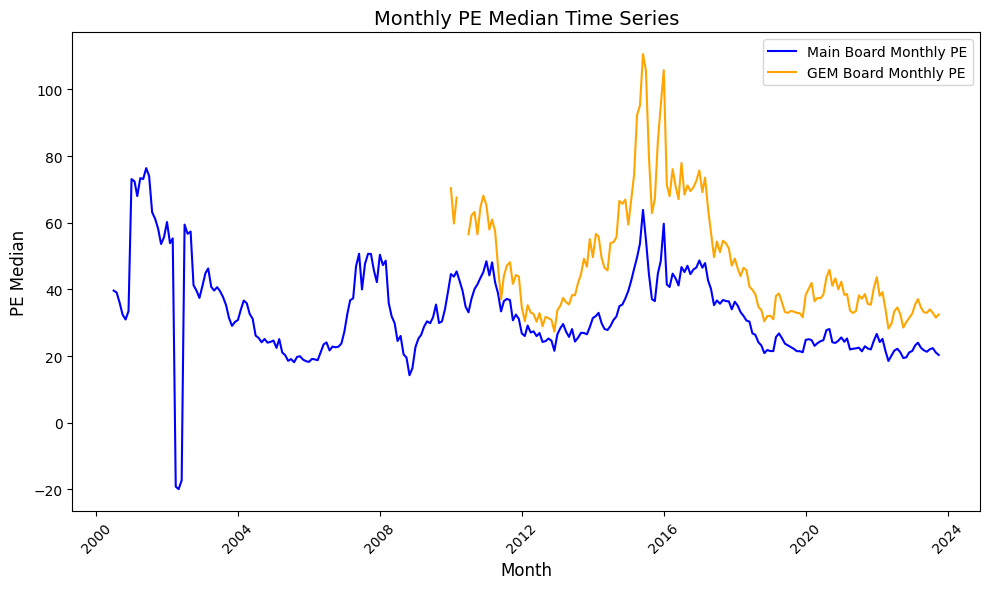

In [122]:

time_series_pe = main_board.groupby('Trdmnt')['monthly_PE'].median()
time_series_pe_gem = GEM_board.groupby('Trdmnt')['monthly_PE'].median()
plt.figure(figsize=(10, 6))

# 绘制 main_board 的 monthly_PE 中位数时间序列图
plt.plot(time_series_pe.index, time_series_pe, label='Main Board Monthly PE', color='blue', linestyle='-')

# 绘制 GEM_board 的 monthly_PE 中位数时间序列图
plt.plot(time_series_pe_gem.index, time_series_pe_gem, label='GEM Board Monthly PE', color='orange', linestyle='-')

# 添加标题和标签
plt.title('Monthly PE Median Time Series', fontsize=14)
plt.xlabel('Month', fontsize=12)
plt.ylabel('PE Median', fontsize=12)
plt.xticks(rotation=45)  # 旋转横轴标签以防重叠
plt.legend()

# 显示图形
plt.tight_layout()
plt.show()

### 3.

In [134]:
data3 = pd.read_csv('problem 3_data.csv',dtype={'Symbol': str})
data3['EndDate'] = pd.to_datetime(data3['EndDate'])
data3 = data3.set_index('EndDate').sort_index()
data3['rev_rate'] = data3.groupby('Symbol')['TotalRevenue'].pct_change()
data3 = data3[(data3.index >= '2011-12-31') & (data3.index <= '2020-12-31')]


In [135]:
data3.isnull().sum()

Symbol             0
TotalRevenue       2
ROEC             243
rev_rate        2269
dtype: int64

In [136]:

data3 = data3.dropna(subset=['TotalRevenue', 'ROEC', 'rev_rate'])

In [ ]:
data3['size']= data3.groupby('Symbol')['Symbol'].transform('count')
data3 = data3[data3['size'] == 10]
data3 = data3.drop(columns=['size'])
data3 = data3.sort_values(by=['Symbol', 'EndDate'])
data3

,Symbol,TotalRevenue,ROEC,rev_rate
EndDate,,,,
2011-12-31,000001,2.908733e+10,0.1914,0.656281
2012-12-31,000001,3.891140e+10,0.1687,0.337744
2013-12-31,000001,5.129400e+10,0.1547,0.318226
2014-12-31,000001,7.063700e+10,0.1630,0.377101
2015-12-31,000001,9.270500e+10,0.1495,0.312414
...,...,...,...,...
2016-12-31,900957,8.062995e+07,0.0075,0.548425
2017-12-31,900957,9.811317e+07,0.0734,0.216833
2018-12-31,900957,1.061131e+08,0.0633,0.081537


In [138]:
len(data3['Symbol'].unique())

1955

In [139]:
roe_series ={}
rev_rate_series = {}
data3['ROE_above_median'] = data3.groupby(data3.index.year)['ROEC'].transform(lambda x: x > x.median())
data3['rev_rate_above_median'] = data3.groupby(data3.index.year)['rev_rate'].transform(lambda x: x > x.median())
data3

,Symbol,TotalRevenue,ROEC,rev_rate,ROE_above_median,rev_rate_above_median
EndDate,,,,,,
2011-12-31,000001,2.908733e+10,0.1914,0.656281,True,True
2012-12-31,000001,3.891140e+10,0.1687,0.337744,True,True
2013-12-31,000001,5.129400e+10,0.1547,0.318226,True,True
2014-12-31,000001,7.063700e+10,0.1630,0.377101,True,True
2015-12-31,000001,9.270500e+10,0.1495,0.312414,True,True
...,...,...,...,...,...,...
2016-12-31,900957,8.062995e+07,0.0075,0.548425,False,True
2017-12-31,900957,9.811317e+07,0.0734,0.216833,True,True
2018-12-31,900957,1.061131e+08,0.0633,0.081537,True,False


In [140]:
data3

,Symbol,TotalRevenue,ROEC,rev_rate,ROE_above_median,rev_rate_above_median
EndDate,,,,,,
2011-12-31,000001,2.908733e+10,0.1914,0.656281,True,True
2012-12-31,000001,3.891140e+10,0.1687,0.337744,True,True
2013-12-31,000001,5.129400e+10,0.1547,0.318226,True,True
2014-12-31,000001,7.063700e+10,0.1630,0.377101,True,True
2015-12-31,000001,9.270500e+10,0.1495,0.312414,True,True
...,...,...,...,...,...,...
2016-12-31,900957,8.062995e+07,0.0075,0.548425,False,True
2017-12-31,900957,9.811317e+07,0.0734,0.216833,True,True
2018-12-31,900957,1.061131e+08,0.0633,0.081537,True,False


In [141]:
import pandas as pd
# 存储结果
roe_ratio_series = {}
rev_rate_ratio_series = {}

# 遍历每一年
for i, year in enumerate(range(2011, 2021)):
    yearly_data = data3[data3.index.year == year]

    # 计算当年所有股票数量
    total_stocks = len(yearly_data['Symbol'].unique())

    # 计算当年满足 ROE_above_median 的股票（按 Symbol 取值）
    roe_stocks = set(yearly_data.loc[yearly_data['ROE_above_median'], 'Symbol'])
    rev_rate_stocks = set(yearly_data.loc[yearly_data['rev_rate_above_median'], 'Symbol'])

    # 记录符合条件的股票：
    if i == 0:  # 2011 年初始化
        valid_roe_stocks = roe_stocks
        valid_rev_rate_stocks = rev_rate_stocks
    else:
        valid_roe_stocks &= roe_stocks  # 交集：必须从 2011 到当前年都满足
        valid_rev_rate_stocks &= rev_rate_stocks

    # 计算比例
    roe_ratio_series[year] = len(valid_roe_stocks) / total_stocks if total_stocks > 0 else 0
    rev_rate_ratio_series[year] = len(valid_rev_rate_stocks) / total_stocks if total_stocks > 0 else 0

# 转换为时间序列
roe_ratio_series = pd.Series(roe_ratio_series)
rev_rate_ratio_series = pd.Series(rev_rate_ratio_series)

# 打印结果
print("ROE 持续高于中位数的股票比例：")
print(roe_ratio_series)

print("\nrev_rate 持续高于中位数的股票比例：")
print(rev_rate_ratio_series)


ROE 持续高于中位数的股票比例：
2011    0.499233
2012    0.388235
2013    0.325831
2014    0.285934
2015    0.246547
2016    0.215345
2017    0.191304
2018    0.163683
2019    0.144246
2020    0.120716
dtype: float64

rev_rate 持续高于中位数的股票比例：
2011    0.499744
2012    0.285934
2013    0.173913
2014    0.128389
2015    0.093095
2016    0.065985
2017    0.040409
2018    0.028133
2019    0.016880
2020    0.013299
dtype: float64


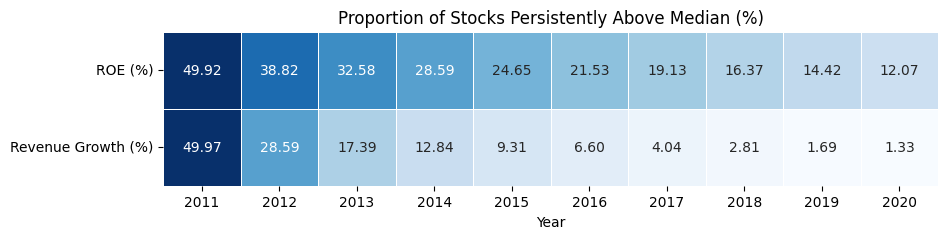

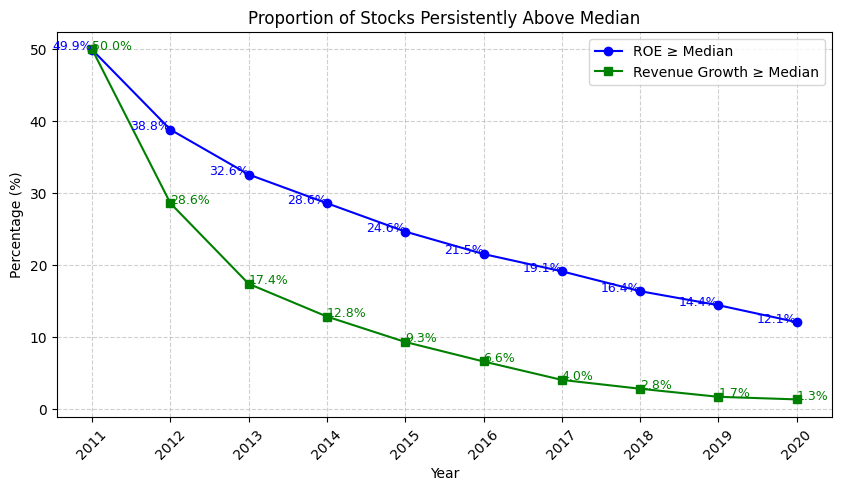

In [142]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 转换为百分比并保留两位小数
roe_ratio_series = (roe_ratio_series * 100).round(2)
rev_rate_ratio_series = (rev_rate_ratio_series * 100).round(2)

# **1. 创建格式化表格**
df_table = pd.DataFrame({
    'ROE (%)': roe_ratio_series, 
    'Revenue Growth (%)': rev_rate_ratio_series
}).T

# **绘制美观表格**
plt.figure(figsize=(10, 2))
sns.heatmap(df_table, annot=True, fmt=".2f", cmap="Blues", linewidths=0.5, cbar=False)
plt.title("Proportion of Stocks Persistently Above Median (%)")
plt.xlabel("Year")
plt.show()

# **2. 绘制折线图**
plt.figure(figsize=(10, 5))
plt.plot(roe_ratio_series.index, roe_ratio_series.values, marker='o', label="ROE ≥ Median", color='blue')
plt.plot(rev_rate_ratio_series.index, rev_rate_ratio_series.values, marker='s', label="Revenue Growth ≥ Median", color='green')

plt.xlabel("Year")
plt.ylabel("Percentage (%)")
plt.title("Proportion of Stocks Persistently Above Median")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(roe_ratio_series.index, rotation=45)

# 显示数值标签
for year, value in roe_ratio_series.items():
    plt.text(year, value, f"{value:.1f}%", ha='right', fontsize=9, color='blue')

for year, value in rev_rate_ratio_series.items():
    plt.text(year, value, f"{value:.1f}%", ha='left', fontsize=9, color='green')

plt.show()
